DSCI 552 Homework 6
===================

- Name: Karan Timmala
- GitHub Username: karantimmala
- USD ID: 1373267232

In [1]:
!pip install xgboost

In [2]:
from pathlib import Path
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_curve, auc, accuracy_score, roc_auc_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline as SklearnPipeline

RANDOM_STATE = 42
CV_FOLDS = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# 1. Tree-Based Methods

## (a) Download the APS Failure data.
### The dataset contains a training set and a test set. The training set contains 60,000 rows, of which 1,000 belong to the positive class and 171 columns, of which one is the class column. All attributes are numeric.

In [3]:
# Skip the CSV metadata and treat the dataset's "na" entries as missing values.
def locate_csv(filename):
    folders = [Path('.'), Path('data'), Path('../data'), Path('upload'), Path('../upload')]
    for folder in folders:
        candidate = folder / filename
        if candidate.is_file():
            return candidate
    raise FileNotFoundError(f'Place {filename} beside the notebook or in a data folder.')


training_data = pd.read_csv(locate_csv('aps_failure_training_set.csv'), skiprows=20, na_values='na')
testing_data = pd.read_csv(locate_csv('aps_failure_test_set.csv'), skiprows=20, na_values='na')
print('Training shape:', training_data.shape)
print('Test shape:', testing_data.shape)
print('Number of predictors:', training_data.shape[1] - 1)

Training shape: (60000, 171)
Test shape: (16000, 171)
Number of predictors: 170


In [4]:
training_data.head()

,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,...,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,...,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,...,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,...,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,...,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0


In [5]:
testing_data.head()

,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,60,0.0,20.0,12.0,0.0,0.0,0.0,0.0,0.0,...,1098.0,138.0,412.0,654.0,78.0,88.0,0.0,0.0,0.0,0.0
1,neg,82,0.0,68.0,40.0,0.0,0.0,0.0,0.0,0.0,...,1068.0,276.0,1620.0,116.0,86.0,462.0,0.0,0.0,0.0,0.0
2,neg,66002,2.0,212.0,112.0,0.0,0.0,0.0,0.0,0.0,...,495076.0,380368.0,440134.0,269556.0,1315022.0,153680.0,516.0,0.0,0.0,0.0
3,neg,59816,NaN,1010.0,936.0,0.0,0.0,0.0,0.0,0.0,...,540820.0,243270.0,483302.0,485332.0,431376.0,210074.0,281662.0,3232.0,0.0,0.0
4,neg,1814,NaN,156.0,140.0,0.0,0.0,0.0,0.0,0.0,...,7646.0,4144.0,18466.0,49782.0,3176.0,482.0,76.0,0.0,0.0,0.0


In [6]:
print(training_data["class"].value_counts())
print(training_data["class"].value_counts(normalize=True))

class
neg    59000
pos     1000
Name: count, dtype: int64
class
neg    0.983333
pos    0.016667
Name: proportion, dtype: float64


In [7]:
print(testing_data["class"].value_counts())
print(testing_data["class"].value_counts(normalize=True))

class
neg    15625
pos      375
Name: count, dtype: int64
class
neg    0.976562
pos    0.023438
Name: proportion, dtype: float64


## (b) Data Preparation
### This data set has missing values. When the number of data with missing values is significant, discarding them is not a good idea.
### (i) Research what types of techniques are usually used for dealing with data with missing values. Pick at least one of them and apply it to this data in the next steps.

Common missing-value treatments include mean, median, or mode imputation;
nearest-neighbor and regression-based imputation; iterative or multiple
imputation; and estimators that handle missing entries directly. Deleting
incomplete observations can remove substantial information from this dataset.

I use **median imputation** because the numerical predictors have skewed
distributions and extreme values. The saved output reports **850,015 missing
entries in the training predictors** and **228,680 in the test predictors**.
After imputation, both counts are **zero**, while all 60,000 training and
16,000 test observations are retained.

Separate median imputers are fitted to the training and test predictors to
follow the PDF's explicit footnote about using test-set statistics for test
imputation. Test labels are excluded. This is the convention required for
this assignment; a standard deployment workflow would normally reuse the
training-fitted imputer when transforming new observations.

In [8]:
X_train_raw = training_data.drop(columns='class').copy()
X_test_raw = testing_data.drop(columns='class').copy()
y_train = training_data['class'].map({'neg': 0, 'pos': 1})
y_test = testing_data['class'].map({'neg': 0, 'pos': 1})

print('Missing entries before imputation (train):', X_train_raw.isna().sum().sum())
print('Missing entries before imputation (test):', X_test_raw.isna().sum().sum())

# Separate test imputation follows the explicit footnote in Homework6.pdf.
train_imputer = SimpleImputer(strategy='median')
test_imputer = SimpleImputer(strategy='median')
X_train = pd.DataFrame(train_imputer.fit_transform(X_train_raw),
                       columns=X_train_raw.columns, index=X_train_raw.index)
X_test = pd.DataFrame(test_imputer.fit_transform(X_test_raw),
                      columns=X_test_raw.columns, index=X_test_raw.index)

print('Missing entries after imputation (train):', X_train.isna().sum().sum())
print('Missing entries after imputation (test):', X_test.isna().sum().sum())

Missing entries before imputation (train): 850015
Missing entries before imputation (test): 228680
Missing entries after imputation (train): 0
Missing entries after imputation (test): 0


### (ii) Coefficient of variation for all 170 predictors

For each median-imputed training predictor, the table below reports
$CV=s/m$, using the sample standard deviation (`ddof=1`). The displayed CVs
are ratios, rather than percentages. For example, `aa_000` has CV about
**2.4509**, whereas `cf_000` has CV about **244.8875**. The latter therefore
has much greater variability relative to its mean.

The largest three CVs are approximately **244.8875 (`cf_000`)**, **244.5074
(`co_000`)**, and **244.3228 (`ad_000`)**. The feature `cd_000` has a sample
standard deviation of zero and consequently CV zero in the displayed table.
High CV alone does not imply that a feature is useful for predicting class.

In [9]:
# Use sample standard deviation and leave CV undefined when a feature mean is zero.
means = X_train.mean()
stds = X_train.std(ddof=1)
cv = stds.div(means.replace(0, np.nan))
variation_table = pd.DataFrame({'Feature': X_train.columns, 'Mean': means.values,
                       'StdDev': stds.values, 'CV': cv.values})
print('CV values calculated for all', len(variation_table), 'predictors (CV = sample SD / mean).')
with pd.option_context('display.max_rows', 170):
    display(variation_table.head())

CV values calculated for all 170 predictors (CV = sample SD / mean).


,Feature,Mean,StdDev,CV
0,aa_000,5.933650e+04,1.454301e+05,2.450938
1,ab_000,1.625000e-01,1.687318e+00,10.383494
2,ac_000,3.362258e+08,7.767625e+08,2.310241
3,ad_000,1.434383e+05,3.504525e+07,244.322816
4,ae_000,6.535000e+00,1.581479e+02,24.200137


### (iii) Correlation matrix

The heatmap below summarizes pairwise correlations among the 170 imputed
training predictors. Its visible warm-colored blocks show groups of
positively correlated features, while many other pairs have correlations
near zero. These patterns suggest that some predictors contain overlapping
information, but do not establish their relationship with the class label.

The constant feature `cd_000`, whose standard deviation is zero in the CV
table, has undefined Pearson correlations, the corresponding blank band
should not be interpreted as a correlation of zero.

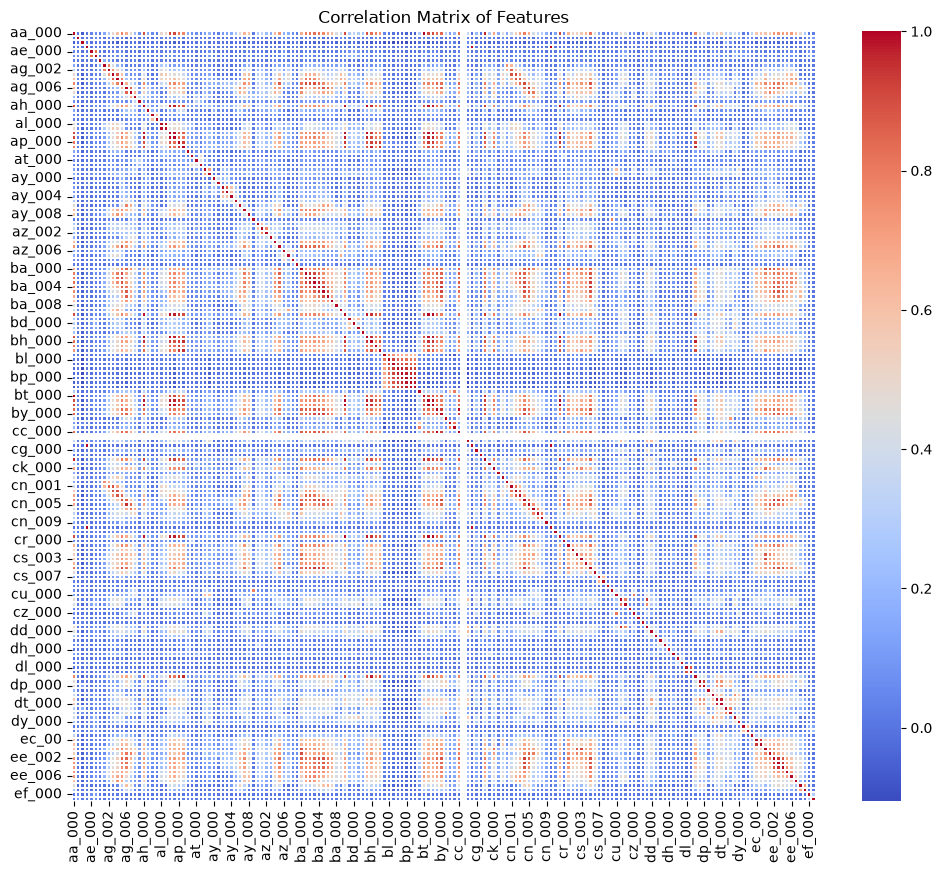

In [10]:
corr_matrix = X_train.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, cmap="coolwarm", linewidths=0.1)
plt.title("Correlation Matrix of Features")
plt.show()

### (iv) Select the $\lfloor\sqrt{170}\rfloor=13$ features with highest CV

Use these features for scatter plots and box plots only. All 170 features remain
in the subsequent models. The calculations and plots below use training data;
test-set counts are reported separately in part (v).

In [11]:
# Select high-CV features for visualization; every model still uses all 170 predictors.
top_k = math.floor(math.sqrt(X_train.shape[1]))
cv_sorted = variation_table.sort_values('CV', ascending=False, na_position='last')
visual_features = cv_sorted.head(top_k)['Feature'].tolist()
display(cv_sorted.head(top_k).reset_index(drop=True))

,Feature,Mean,StdDev,CV
0,cf_000,143107.534133,3.504525e+07,244.887517
1,co_000,143330.017733,3.504525e+07,244.507385
2,ad_000,143438.292067,3.504525e+07,244.322816
3,cs_009,770.509700,1.833278e+05,237.930554
4,dh_000,4392.640833,5.412441e+05,123.216097
5,dj_000,37.271333,4.379166e+03,117.494225
6,ag_000,219.157733,2.036364e+04,92.917755
7,as_000,125.407900,1.095219e+04,87.332500
8,ay_009,1149.619633,9.741156e+04,84.733735
9,ak_000,907.660700,7.299859e+04,80.424975


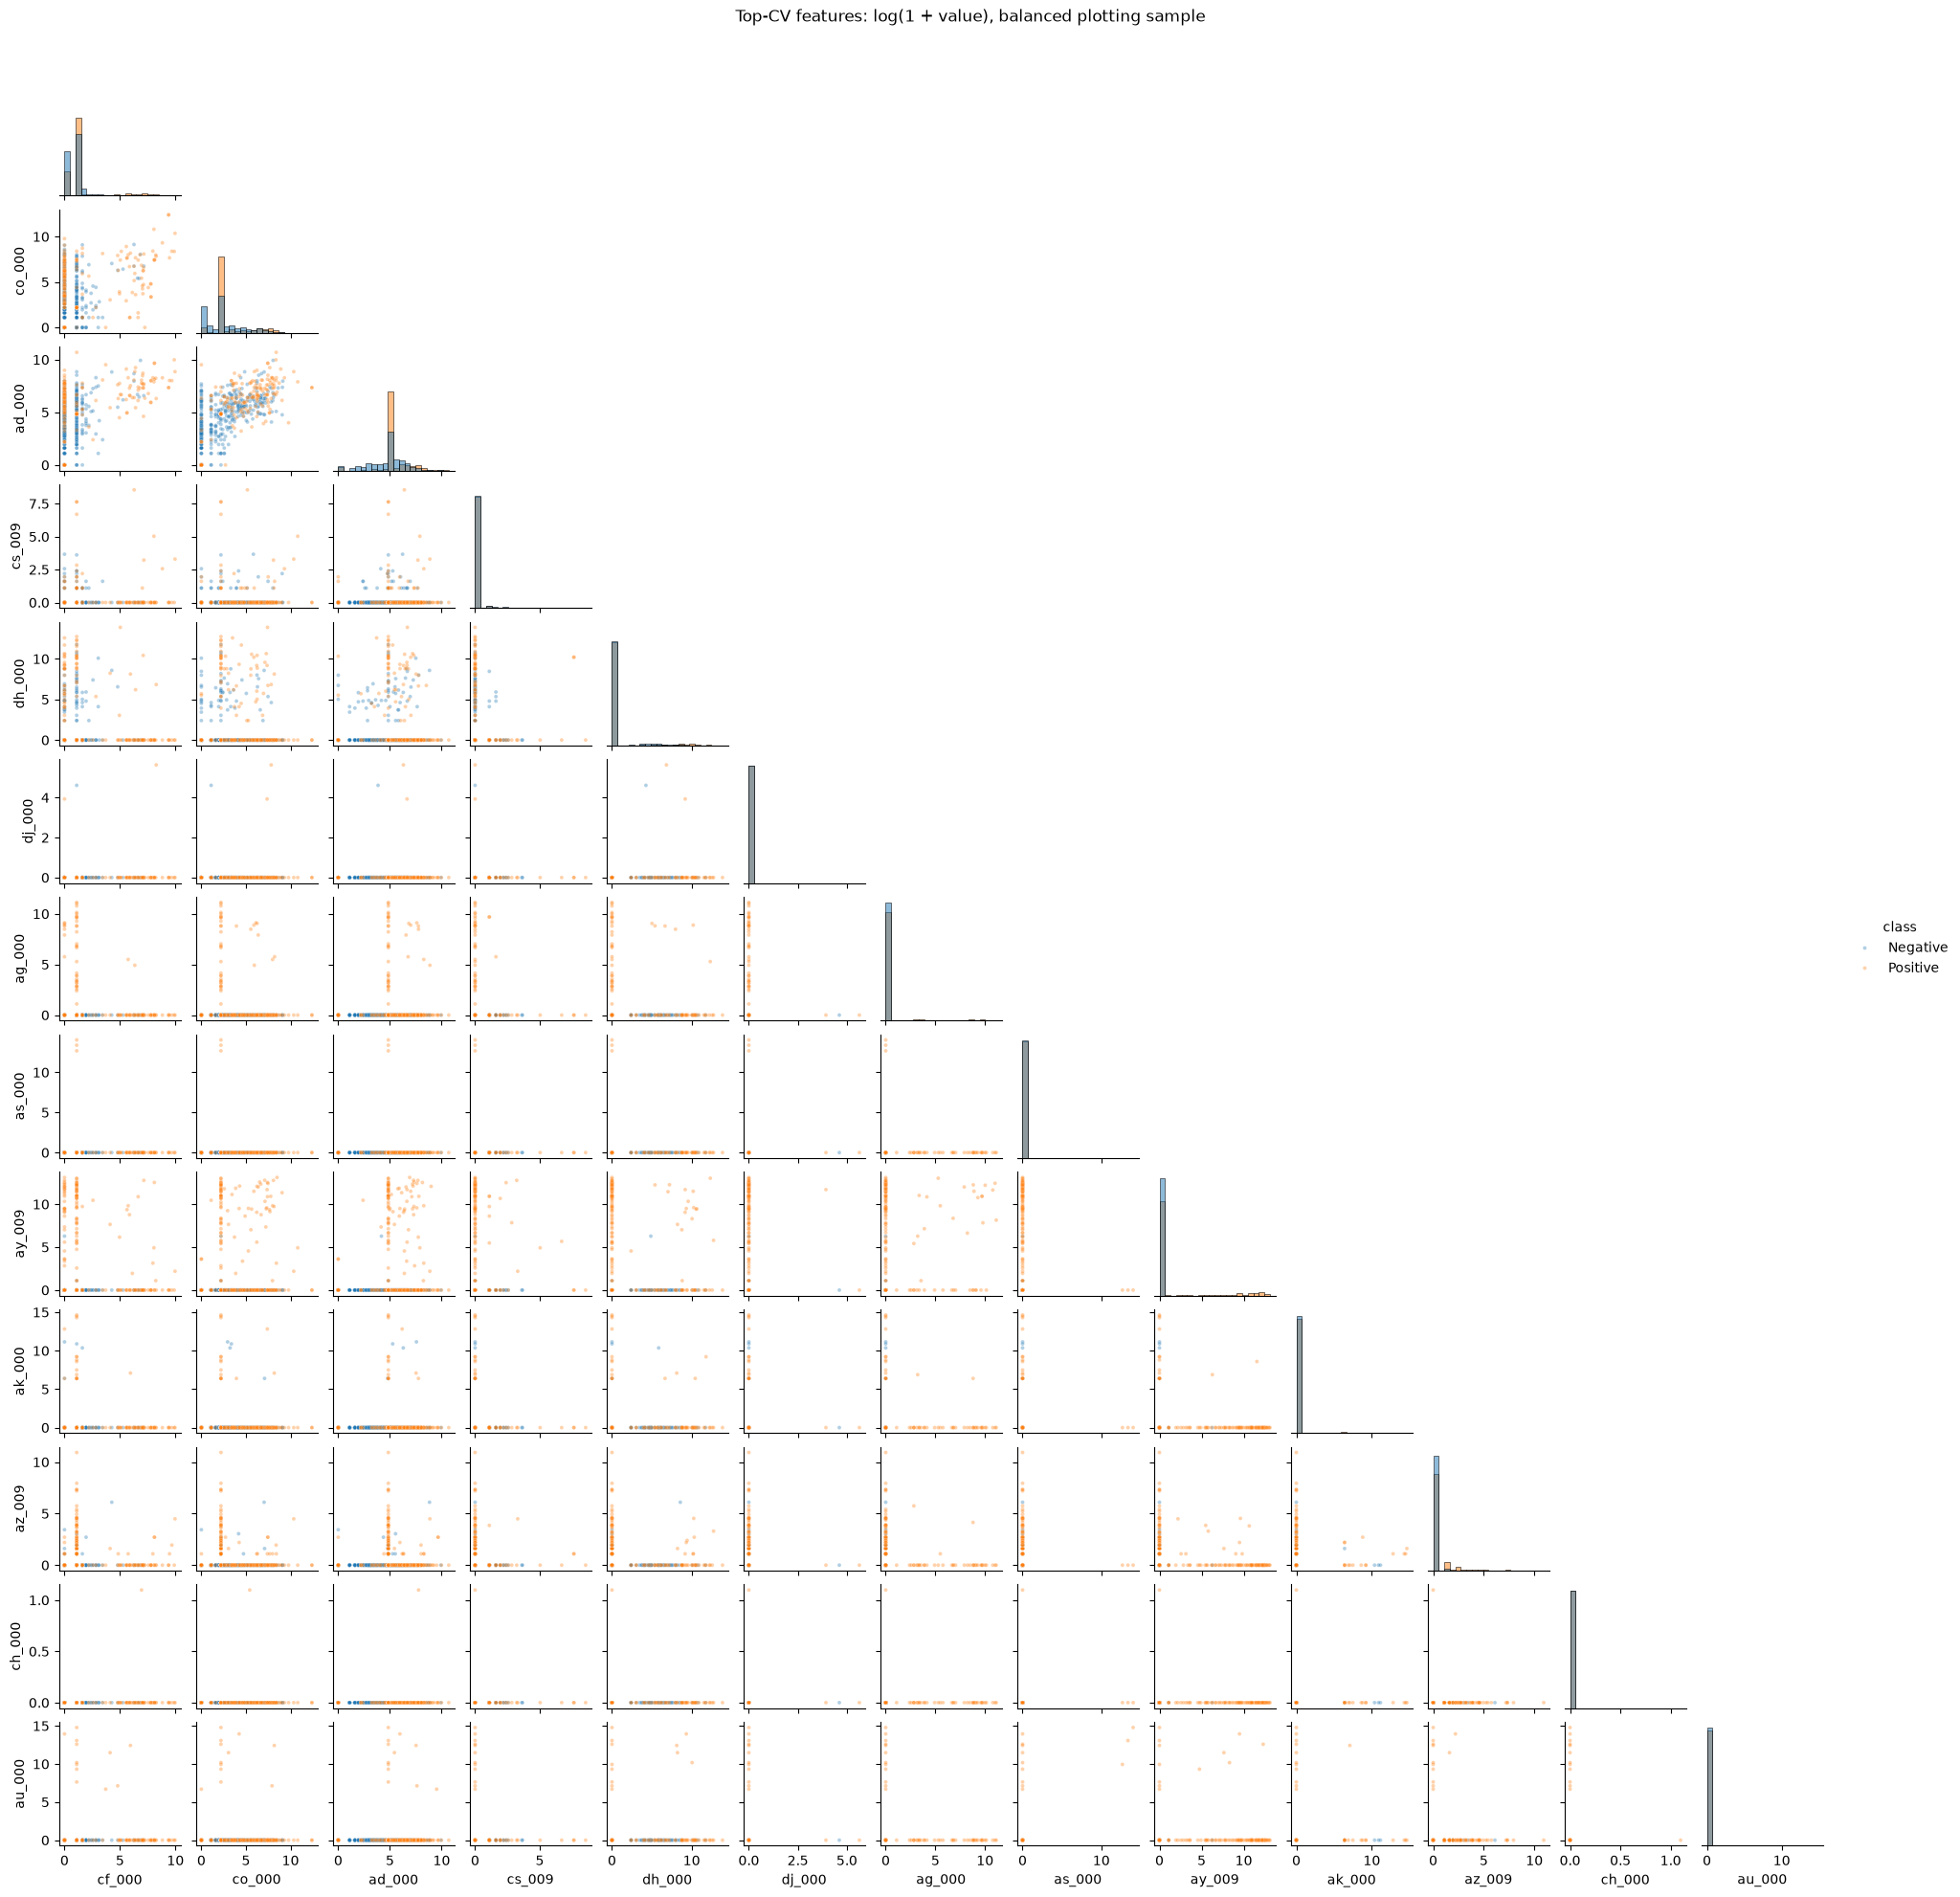

In [12]:
plot_df = X_train[visual_features].copy()
plot_df['class'] = y_train.map({0: 'Negative', 1: 'Positive'})

# Balance only the plotting sample so the rare class is visible.
plot_sample = pd.concat([
    group.sample(n=min(500, len(group)), random_state=RANDOM_STATE)
    for _, group in plot_df.groupby('class', sort=True)
])
scatter_df = plot_sample.copy()
scatter_df[visual_features] = np.log1p(scatter_df[visual_features])
scatter_grid = sns.pairplot(
    scatter_df, vars=visual_features, hue='class', hue_order=['Negative', 'Positive'],
    diag_kind='hist', corner=True, height=1.5,
    plot_kws={'alpha': 0.35, 's': 8}, diag_kws={'bins': 20}
)
scatter_grid.fig.suptitle('Top-CV features: log(1 + value), balanced plotting sample', y=1.02)
plt.show()

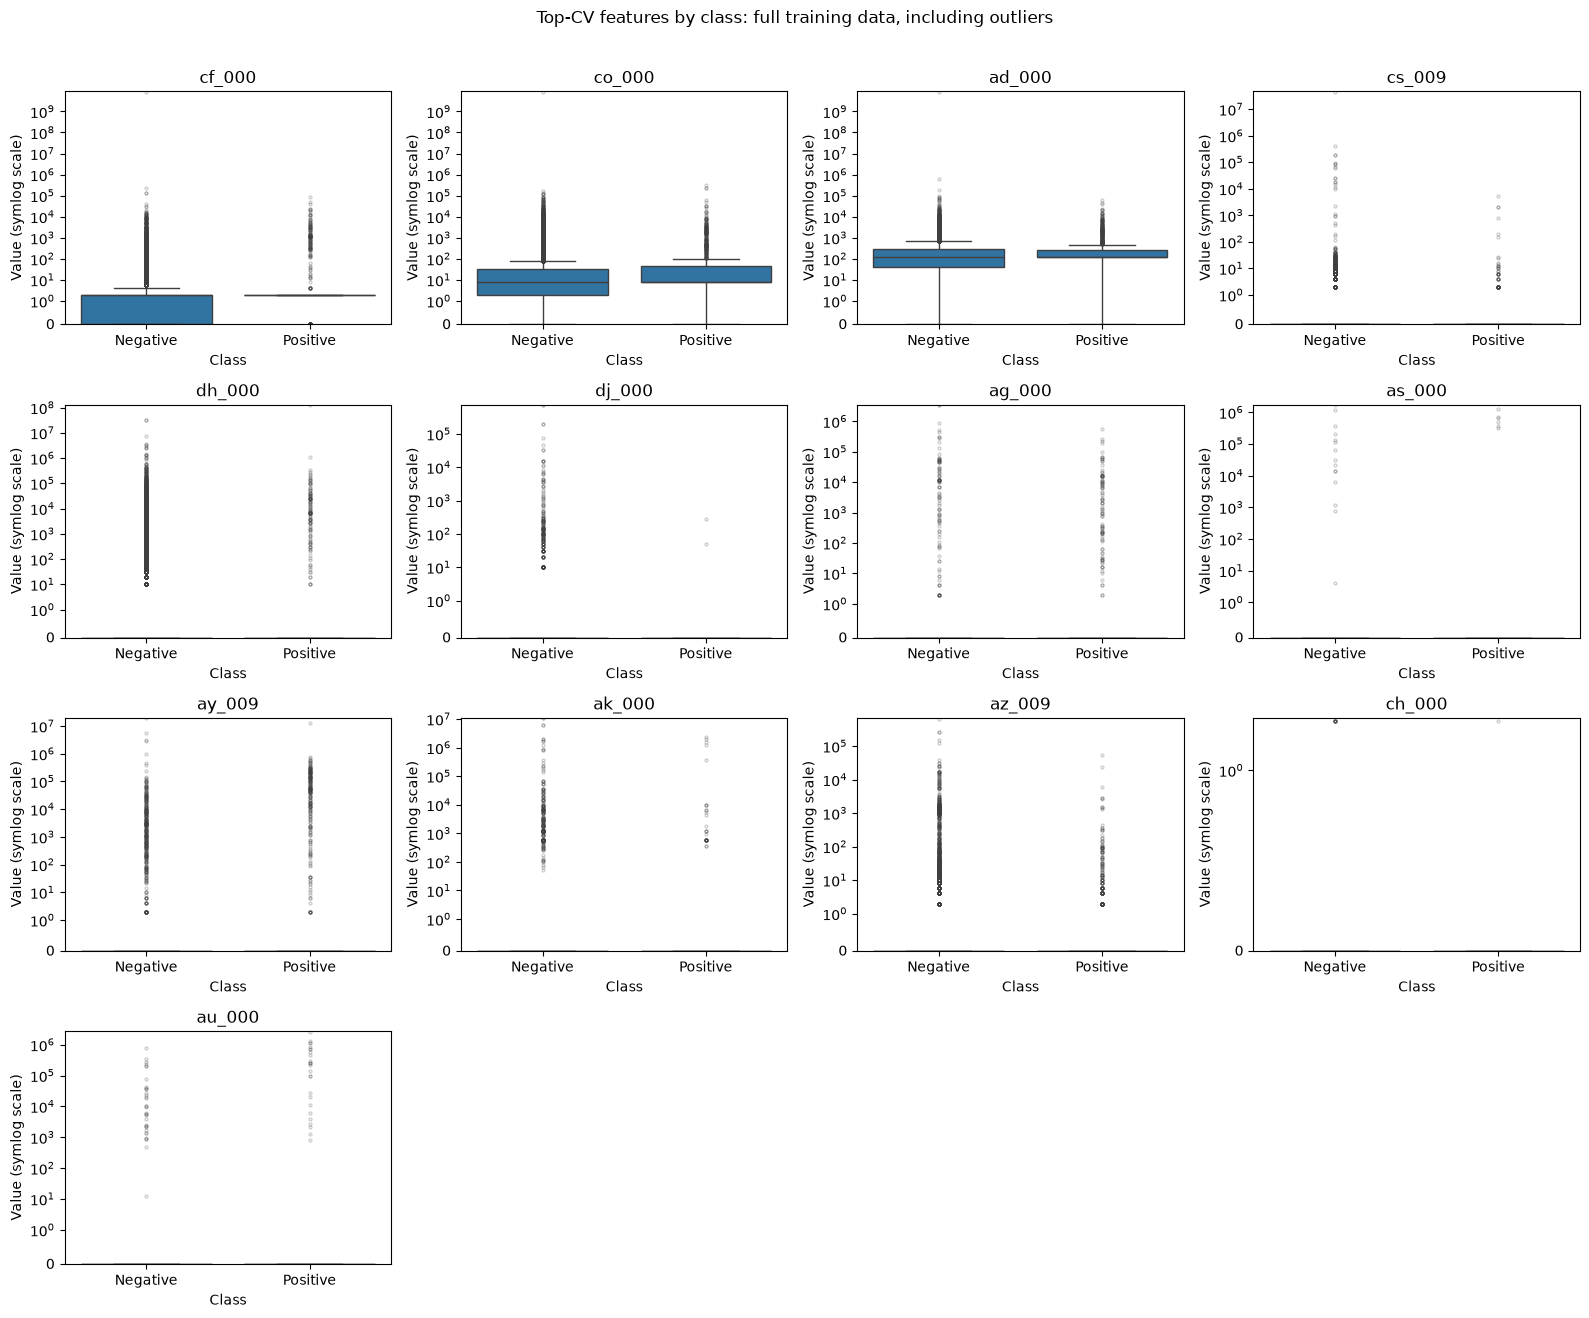

In [13]:
# A symmetric-log scale displays both zero values and large outliers.
box_df = X_train[visual_features].copy()
box_df['class'] = y_train.map({0: 'Negative', 1: 'Positive'})
fig, axes = plt.subplots(4, 4, figsize=(16, 13))
for ax, feature in zip(axes.ravel(), visual_features):
    sns.boxplot(data=box_df, x='class', y=feature,
                order=['Negative', 'Positive'], showfliers=True,
                flierprops={'markersize': 2, 'alpha': 0.25}, ax=ax)
    ax.set_yscale('symlog', linthresh=1)
    ax.set_ylim(bottom=0)
    ax.set_title(feature)
    ax.set_xlabel('Class')
    ax.set_ylabel('Value (symlog scale)')
for ax in axes.ravel()[len(visual_features):]:
    ax.set_visible(False)
fig.suptitle('Top-CV features by class: full training data, including outliers', y=1.01)
plt.tight_layout()
plt.show()

### Interpretation of the selected-feature plots

The selected 13 predictors are `cf_000`, `co_000`, `ad_000`, `cs_009`,
`dh_000`, `dj_000`, `ag_000`, `as_000`, `ay_009`, `ak_000`, `az_009`,
`ch_000`, and `au_000`. Their CVs range from approximately **68.8828** to
**244.8875** in the displayed results.

The scatter matrix contains **500 negative and 500 positive observations**
and displays `log(1 + value)`, which retains zeros. The plots show many
observations concentrated near zero and a small number of much larger
values. Some feature pairs show visible association, but the class colors
overlap rather than forming completely separate groups.

The box plots use the full training data and a symmetric-log scale. For
several sparse predictors, the median and quartiles coincide at zero while
outlier markers extend far above it. The class distributions of `co_000`
and `ad_000` show differences in their centers, but the observed ranges
still overlap. These are descriptive observations, not significance tests.

**The plots alone cannot establish statistical significance or predictive
importance.** High CV describes relative variability. Visible overlap in a
two-feature projection does not rule out useful multivariate relationships.
The balanced scatter sample is used only for visualization; all 170
predictors and the original training observations are used for modeling.

### (v) Determine the positive/negative counts and assess imbalance

In [14]:
class_counts = pd.DataFrame({
    'Training': y_train.value_counts().reindex([0, 1]),
    'Test': y_test.value_counts().reindex([0, 1])
}).rename(index={0: 'Negative', 1: 'Positive'})
class_counts['Combined'] = class_counts['Training'] + class_counts['Test']
display(class_counts)
print(f'Training positive percentage: {100 * y_train.mean():.4f}%')
print(f'Test positive percentage: {100 * y_test.mean():.4f}%')

,Training,Test,Combined
class,,,
Negative,59000,15625,74625
Positive,1000,375,1375


Training positive percentage: 1.6667%
Test positive percentage: 2.3438%


The displayed counts confirm a highly imbalanced dataset:

| Split | Negative | Positive | Positive share |
|---|---:|---:|---:|
| Training | 59,000 | 1,000 | 1.6667% |
| Test | 15,625 | 375 | 2.3438% |
| Combined | 74,625 | 1,375 | 1.8092% |

The training ratio is **59 negatives for each positive**. A model can achieve
high overall accuracy while missing many failures, so positive-class recall
and false negatives are important when interpreting the confusion matrices.

### (c) Train a random forest to classify the data set. Do NOT compensate for class imbalance in the data set. Calculate the confusion matrix, ROC, AUC, and misclassification for training and test sets and report them (You may use pROC package). Calculate Out of Bag error estimate for your random forest and compare it to the test error.

In [15]:
# Bootstrap sampling supplies the observations used to estimate OOB error.
baseline_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=4,
    oob_score=True
)

baseline_forest.fit(X_train, y_train)

y_train_pred = baseline_forest.predict(X_train)
y_test_pred = baseline_forest.predict(X_test)

cm_train = confusion_matrix(y_train, y_train_pred)
cm_test = confusion_matrix(y_test, y_test_pred)

print("Train Confusion Matrix:\n", cm_train)
print("\nTest Confusion Matrix:\n", cm_test)

Train Confusion Matrix:
 [[59000     0]
 [    1   999]]

Test Confusion Matrix:
 [[15610    15]
 [  106   269]]


In [16]:
# ROC and AUC use positive-class probabilities rather than predicted labels.
y_train_prob = baseline_forest.predict_proba(X_train)[:, 1]
y_test_prob = baseline_forest.predict_proba(X_test)[:, 1]

fpr_train, tpr_train, _ = roc_curve(y_train, y_train_prob)
fpr_test, tpr_test, _ = roc_curve(y_test, y_test_prob)

auc_train = auc(fpr_train, tpr_train)
auc_test = auc(fpr_test, tpr_test)

print("Train AUC:", auc_train)
print("Test AUC:", auc_test)

Train AUC: 1.0
Test AUC: 0.9927564799999999


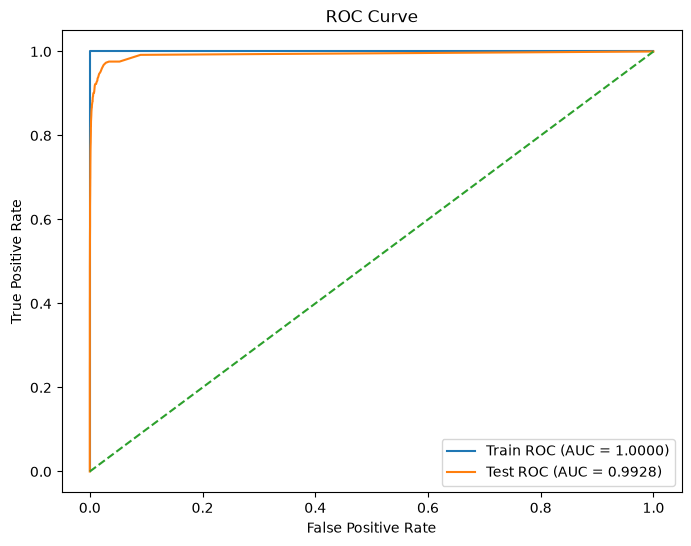

In [17]:
plt.figure(figsize=(8,6))

plt.plot(fpr_train, tpr_train, label=f"Train ROC (AUC = {auc_train:.4f})")
plt.plot(fpr_test, tpr_test, label=f"Test ROC (AUC = {auc_test:.4f})")

plt.plot([0,1], [0,1], '--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

In [18]:
train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_test_pred)

train_error = 1 - train_acc
test_error = 1 - test_acc

print("Train Misclassification Error:", train_error)
print("Test Misclassification Error:", test_error)

Train Misclassification Error: 1.666666666666483e-05
Test Misclassification Error: 0.0075625000000000275


In [19]:
# Compare the internal OOB estimate with error on the supplied test set.
oob_error = 1 - baseline_forest.oob_score_
print(f'OOB error: {oob_error:.6f}')
print(f'Test error: {test_error:.6f}')
print(f'Test minus OOB error: {test_error - oob_error:+.6f}')

OOB error: 0.006167
Test error: 0.007563
Test minus OOB error: +0.001396


### Interpretation of the uncompensated random forest

Rows in the confusion matrices are actual classes and columns are predicted
classes, ordered Negative then Positive. On the training data, the forest
correctly classifies 59,000 negatives and 999 positives, with one false
negative and no false positives. Its training error is approximately
**0.00167%**, and its reported training AUC is **1.000000**.

On the test set, it produces **15 false positives** and
**106 false negatives**, correctly detecting **269 of 375
positive failures**. Positive recall is **71.73%**,
test error is **0.75625%**, and test AUC is
**0.992756**. Thus, strong overall discrimination and a low total error
coexist with a substantial number of missed positive cases at the default
threshold.

The reported OOB error is **0.6167%**, below the test error by
approximately **0.1396 percentage points**.
OOB and test results are reasonably close, although they are estimates from
different observations. The near-perfect training fit should not be treated
as an independent estimate of generalization performance.

### (d) Research how class imbalance is addressed in random forests. Compensate for class imbalance in your random forest and repeat 1c. Compare the results with those of 1c.
Class imbalance in Random Forests can be handled using techniques such as:
- Assigning class weights (giving more importance to minority class)
- Oversampling the minority class (e.g., SMOTE)
- Undersampling the majority class
- Using balanced versions of Random Forest (e.g., Balanced Random Forest)

In this problem, class imbalance was handled using **class weights**.

C:\Users\karan\anaconda3\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


Balanced Train Confusion Matrix:
 [[58986    14]
 [    0  1000]]

Balanced Test Confusion Matrix:
 [[15571    54]
 [   99   276]]
Balanced Train AUC: 1.0
Balanced Test AUC: 0.9944034133333333


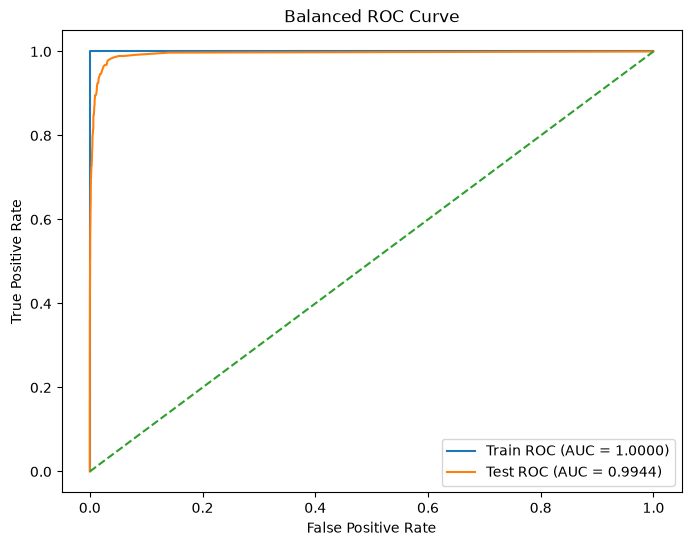

Balanced Train Misclassification Error: 0.00023333333333330764
Balanced Test Misclassification Error: 0.00956250000000003
Balanced OOB Score: 0.9797833333333333
Balanced OOB Error: 0.02021666666666666


In [20]:
# Inverse-frequency class weights increase the influence of minority observations.
weighted_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=4,
    oob_score=True,
    class_weight="balanced"
)

weighted_forest.fit(X_train, y_train)

y_train_pred_bal = weighted_forest.predict(X_train)
y_test_pred_bal = weighted_forest.predict(X_test)

cm_train_bal = confusion_matrix(y_train, y_train_pred_bal)
cm_test_bal = confusion_matrix(y_test, y_test_pred_bal)

print("Balanced Train Confusion Matrix:\n", cm_train_bal)
print("\nBalanced Test Confusion Matrix:\n", cm_test_bal)

y_train_prob_bal = weighted_forest.predict_proba(X_train)[:, 1]
y_test_prob_bal = weighted_forest.predict_proba(X_test)[:, 1]

fpr_train_bal, tpr_train_bal, _ = roc_curve(y_train, y_train_prob_bal)
fpr_test_bal, tpr_test_bal, _ = roc_curve(y_test, y_test_prob_bal)

auc_train_bal = auc(fpr_train_bal, tpr_train_bal)
auc_test_bal = auc(fpr_test_bal, tpr_test_bal)

print("Balanced Train AUC:", auc_train_bal)
print("Balanced Test AUC:", auc_test_bal)

plt.figure(figsize=(8, 6))

plt.plot(fpr_train_bal, tpr_train_bal, label=f"Train ROC (AUC = {auc_train_bal:.4f})")
plt.plot(fpr_test_bal, tpr_test_bal, label=f"Test ROC (AUC = {auc_test_bal:.4f})")

plt.plot([0, 1], [0, 1], '--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Balanced ROC Curve")
plt.legend()
plt.show()

train_acc_bal = accuracy_score(y_train, y_train_pred_bal)
test_acc_bal = accuracy_score(y_test, y_test_pred_bal)

train_error_bal = 1 - train_acc_bal
test_error_bal = 1 - test_acc_bal

print("Balanced Train Misclassification Error:", train_error_bal)
print("Balanced Test Misclassification Error:", test_error_bal)

oob_score_bal = weighted_forest.oob_score_
oob_error_bal = 1 - oob_score_bal

print("Balanced OOB Score:", oob_score_bal)
print("Balanced OOB Error:", oob_error_bal)

### Comparison of the random forests

The saved results show the following changes after adding class weights:

| Metric | Uncompensated forest | Class-weighted forest |
|---|---:|---:|
| Training error | 0.00167% | 0.02333% |
| Test error | 0.75625% | 0.95625% |
| Test false positives | 15 | 54 |
| Test false negatives | 106 | 99 |
| Test positive recall | 71.73% | 73.60% |
| Test AUC | 0.992756 | 0.994403 |
| Reported OOB error | 0.6167% | 2.0217% |

Class weighting detects **7 additional positive failures**: false negatives
decrease from **106 to 99**, and recall improves by approximately **1.87
percentage points**. This comes with **39 additional false positives**,
increasing false alarms from **15 to 54**. Total test error consequently
increases by **0.20 percentage points**, even though the test AUC improves.
The weighted model therefore improves minority-class detection slightly,
with a trade-off in false alarms and overall misclassification.

Its training matrix contains 14 false positives and no false negatives,
whereas the uncompensated forest has one false negative and no false
positives. Both models report training AUC **1.000000**; AUC assesses score
ranking, while the confusion matrix describes predictions at one threshold.

**OOB limitation in the saved run:** The weighted-forest output includes a
warning that some observations do not have OOB scores. Its reported OOB
error of **2.0217%** should therefore be treated cautiously
and verified by rerunning that model cell. In addition, the forest's OOB
calculation does not refit the imputer separately for each bootstrap sample.

In [21]:
rf_comparison = pd.DataFrame({
    'Uncompensated RF': {
        'Train error': train_error, 'Test error': test_error, 'OOB error': oob_error,
        'Train AUC': auc_train, 'Test AUC': auc_test,
        'Test false positives': cm_test[0, 1], 'Test false negatives': cm_test[1, 0],
        'Test positive recall': cm_test[1, 1] / cm_test[1].sum()
    },
    'Class-weighted RF': {
        'Train error': train_error_bal, 'Test error': test_error_bal, 'OOB error': oob_error_bal,
        'Train AUC': auc_train_bal, 'Test AUC': auc_test_bal,
        'Test false positives': cm_test_bal[0, 1], 'Test false negatives': cm_test_bal[1, 0],
        'Test positive recall': cm_test_bal[1, 1] / cm_test_bal[1].sum()
    }
})
display(rf_comparison.round(6))
print(f'Class weighting changes test error by {test_error_bal - test_error:+.6f}.')
recall_difference = cm_test_bal[1, 1] / cm_test_bal[1].sum() - cm_test[1, 1] / cm_test[1].sum()
print(f'Class weighting changes positive recall by {100 * recall_difference:+.3f} percentage points.')

,Uncompensated RF,Class-weighted RF
Train error,0.000017,0.000233
Test error,0.007563,0.009563
OOB error,0.006167,0.020217
Train AUC,1.000000,1.000000
Test AUC,0.992756,0.994403
Test false positives,15.000000,54.000000
Test false negatives,106.000000,99.000000
Test positive recall,0.717333,0.736000


Class weighting changes test error by +0.002000.
Class weighting changes positive recall by +1.867 percentage points.


## (e) XGBoost and Model Trees
### In the case of a univariate tree, only one input dimension is used at a tree split. In a multivariate tree, or model tree, at a decision node all input dimensions can be used and thus it is more general. In univariate classification trees, majority polling is used at each node to determine the split of that node as the decision rule. In model trees, a (linear) model that relies on all of the variables is used to determine the split of that node (i.e. instead of using Xj > s as the decision rule, one has summation of βjXj > s. as the decision rule). Alternatively, in a regression tree, instead of using average in the region associated with each node, a linear regression model is used to determine the value associated with that node.

### One of the methods that can be used at each node is Logistic Regression. Because the number of variables is large in this problem, one can use L1-penalized logistic regression at each node. You can use XGBoost to fit the model tree. Determine α (the regularization term) using cross-validation. Train the model for the APS data set without compensation for class imbalance. Use one of 5 fold, 10 fold, and leave-one-out cross validation methods to estimate the error of your trained model and compare it with the test error. Report the Confusion Matrix, ROC, and AUC for training and test sets.

**Implementation clarification:** The assignment permits XGBoost. The model
below uses boosted trees with logistic loss and an L1 penalty on leaf weights
(`reg_alpha`). Ordinary XGBoost trees do not fit a separate logistic-regression
model at each decision node. Thus this implements the apparent intended
L1-regularized XGBoost workflow, rather than claiming to be a literal logistic
model tree. `reg_lambda` controls L2 regularization and is not the parameter
being tuned here.

In [22]:
from xgboost import XGBClassifier

# Fit imputation within each fold, using the original missing-value matrix.
xgb_pipeline = SklearnPipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('xgb', XGBClassifier(objective='binary:logistic', eval_metric='logloss',
                          random_state=RANDOM_STATE, n_jobs=4))
])
alpha_candidates = [0, 0.01, 0.1, 1, 10]
xgb_search = GridSearchCV(
    xgb_pipeline, {'xgb__reg_alpha': alpha_candidates},
    cv=CV_FOLDS, scoring='accuracy', n_jobs=1, refit=True
)
xgb_search.fit(X_train_raw, y_train)
best_alpha = xgb_search.best_params_['xgb__reg_alpha']
cv_error_xgb = 1 - xgb_search.best_score_
print('Selected reg_alpha:', best_alpha)
print(f'Selected-model 5-fold CV error: {cv_error_xgb:.6f}')

Selected reg_alpha: 0.01
Selected-model 5-fold CV error: 0.006333


In [23]:
# GridSearchCV already refits the selected pipeline on the full training set.
xgb_final = xgb_search.best_estimator_
y_train_pred_xgb = xgb_final.predict(X_train_raw)

# Test features were imputed separately above, following the PDF footnote.
y_test_pred_xgb = xgb_final.predict(X_test)
cm_train_xgb = confusion_matrix(y_train, y_train_pred_xgb, labels=[0, 1])
cm_test_xgb = confusion_matrix(y_test, y_test_pred_xgb, labels=[0, 1])
print('XGBoost training confusion matrix:\n', cm_train_xgb)
print('XGBoost test confusion matrix:\n', cm_test_xgb)

XGBoost training confusion matrix:
 [[59000     0]
 [    1   999]]
XGBoost test confusion matrix:
 [[15609    16]
 [   86   289]]


In [24]:
y_train_prob_xgb = xgb_final.predict_proba(X_train_raw)[:, 1]
y_test_prob_xgb = xgb_final.predict_proba(X_test)[:, 1]
fpr_train_xgb, tpr_train_xgb, _ = roc_curve(y_train, y_train_prob_xgb)
fpr_test_xgb, tpr_test_xgb, _ = roc_curve(y_test, y_test_prob_xgb)
auc_train_xgb = roc_auc_score(y_train, y_train_prob_xgb)
auc_test_xgb = roc_auc_score(y_test, y_test_prob_xgb)
print(f'XGBoost training AUC: {auc_train_xgb:.6f}')
print(f'XGBoost test AUC: {auc_test_xgb:.6f}')

XGBoost training AUC: 1.000000
XGBoost test AUC: 0.993658


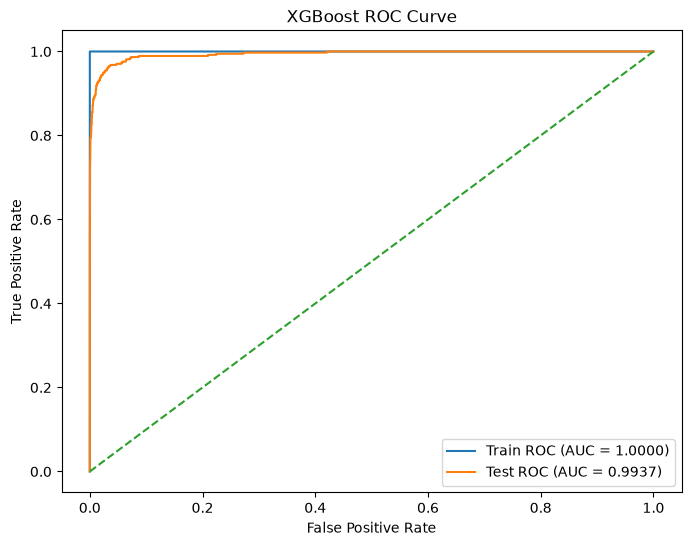

In [25]:
plt.figure(figsize=(8,6))

plt.plot(fpr_train_xgb, tpr_train_xgb, label=f"Train ROC (AUC = {auc_train_xgb:.4f})")
plt.plot(fpr_test_xgb, tpr_test_xgb, label=f"Test ROC (AUC = {auc_test_xgb:.4f})")

plt.plot([0,1], [0,1], '--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("XGBoost ROC Curve")
plt.legend()
plt.show()

In [26]:
train_error_xgb = 1 - accuracy_score(y_train, y_train_pred_xgb)
test_error_xgb = 1 - accuracy_score(y_test, y_test_pred_xgb)
print(f'Training misclassification error: {train_error_xgb:.6f}')
print(f'5-fold CV misclassification error: {cv_error_xgb:.6f}')
print(f'Test misclassification error: {test_error_xgb:.6f}')
print(f'Test minus CV error: {test_error_xgb - cv_error_xgb:+.6f}')

Training misclassification error: 0.000017
5-fold CV misclassification error: 0.006333
Test misclassification error: 0.006375
Test minus CV error: +0.000042


### Cross-validation and test comparison

Five shuffled stratified folds were used to select the L1 regularization
parameter. The search selected **alpha = 0.01**, with mean CV
misclassification error **0.006333**, or approximately
**0.6333%**. Imputation was fitted separately within each fold,
and the chosen pipeline was refitted on the full training set.

The training confusion matrix contains **one false negative and no false
positives**, giving error **0.00167%**. The reported
training AUC is **1.000000** after rounding.

The test matrix contains **16 false positives** and
**86 false negatives**, with **289 of 375 positives**
correctly detected. Test error is **0.63750%**,
positive recall is **77.07%**, and test AUC is
**0.993658**. The high AUC indicates strong ranking performance, while
the 86 missed failures show that the default threshold still leaves room
to improve positive-class detection.

Test and CV errors differ by approximately **0.0042 percentage points**,
so they are very similar in this run. This supports comparable performance
on these evaluations, but does not prove that overfitting is absent. The
CV score was also used to select alpha, and the training metrics are
in-sample results.

### (f) Use SMOTE (Synthetic Minority Over-sampling Technique) to pre-process your data to compensate for class imbalance. Train XGBoost with L1-penalized logistic regression at each node using the pre-processed data and repeat 1e. Do not forget that there is a right and a wrong way of cross validation here. Compare the uncompensated case with SMOTE case.

In [27]:
from imblearn.pipeline import Pipeline as ImbalancedPipeline
from imblearn.over_sampling import SMOTE

# Both imputation and SMOTE are fitted only on each CV training partition.
smote_pipeline = ImbalancedPipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('smote', SMOTE(random_state=RANDOM_STATE)),
    ('xgb', XGBClassifier(objective='binary:logistic', eval_metric='logloss',
                          random_state=RANDOM_STATE, n_jobs=4))
])
smote_search = GridSearchCV(
    smote_pipeline, {'xgb__reg_alpha': alpha_candidates},
    cv=CV_FOLDS, scoring='accuracy', n_jobs=1, refit=True
)
smote_search.fit(X_train_raw, y_train)
best_alpha_smote = smote_search.best_params_['xgb__reg_alpha']
cv_error_smote = 1 - smote_search.best_score_
print('Selected SMOTE reg_alpha:', best_alpha_smote)
print(f'Selected-model 5-fold CV error: {cv_error_smote:.6f}')
resampled_counts = y_train.value_counts().sort_index().copy()
for label, added in smote_search.best_estimator_.named_steps['smote'].sampling_strategy_.items():
    resampled_counts.loc[label] += added
print('Final full-training class counts after SMOTE:', resampled_counts.to_dict())

Selected SMOTE reg_alpha: 0.01
Selected-model 5-fold CV error: 0.006317
Final full-training class counts after SMOTE: {0: 59000, 1: 59000}


SMOTE model confusion matrix: original 60,000 training observations:
 [[59000     0]
 [    1   999]]
SMOTE model test confusion matrix:
 [[15557    68]
 [   56   319]]
Training AUC: 0.999992
Test AUC: 0.991278
Training misclassification error: 0.000017
5-fold CV misclassification error: 0.006317
Test misclassification error: 0.007750
Test minus CV error: +0.001433


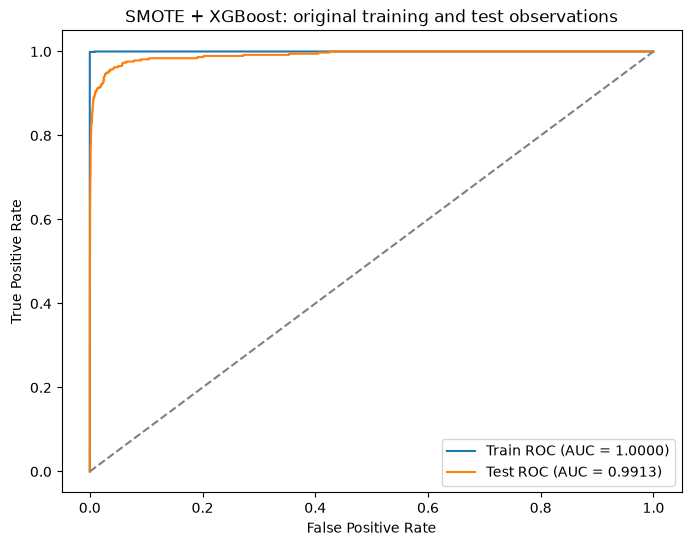

,XGBoost without SMOTE,XGBoost with SMOTE
Selected alpha,0.010000,0.010000
CV error,0.006333,0.006317
Train error (original data),0.000017,0.000017
Test error,0.006375,0.007750
Train AUC (original data),1.000000,0.999992
Test AUC,0.993658,0.991278
Test false positives,16.000000,68.000000
Test false negatives,86.000000,56.000000
Test positive recall,0.770667,0.850667


SMOTE minus uncompensated XGBoost:
False negatives: -30; false positives: +52
Positive recall change: +8.000 percentage points
Test error change: +0.001375
Test AUC change: -0.002380


In [28]:
xgb_smote_final = smote_search.best_estimator_

# Evaluate the original observations; prediction does not apply SMOTE.
y_train_pred_sm = xgb_smote_final.predict(X_train_raw)
y_test_pred_sm = xgb_smote_final.predict(X_test)
y_train_prob_sm = xgb_smote_final.predict_proba(X_train_raw)[:, 1]
y_test_prob_sm = xgb_smote_final.predict_proba(X_test)[:, 1]

cm_train_sm = confusion_matrix(y_train, y_train_pred_sm, labels=[0, 1])
cm_test_sm = confusion_matrix(y_test, y_test_pred_sm, labels=[0, 1])
auc_train_sm = roc_auc_score(y_train, y_train_prob_sm)
auc_test_sm = roc_auc_score(y_test, y_test_prob_sm)
train_error_sm = 1 - accuracy_score(y_train, y_train_pred_sm)
test_error_sm = 1 - accuracy_score(y_test, y_test_pred_sm)

print('SMOTE model confusion matrix: original 60,000 training observations:\n', cm_train_sm)
print('SMOTE model test confusion matrix:\n', cm_test_sm)
print(f'Training AUC: {auc_train_sm:.6f}')
print(f'Test AUC: {auc_test_sm:.6f}')
print(f'Training misclassification error: {train_error_sm:.6f}')
print(f'5-fold CV misclassification error: {cv_error_smote:.6f}')
print(f'Test misclassification error: {test_error_sm:.6f}')
print(f'Test minus CV error: {test_error_sm - cv_error_smote:+.6f}')

fpr_train_sm, tpr_train_sm, _ = roc_curve(y_train, y_train_prob_sm)
fpr_test_sm, tpr_test_sm, _ = roc_curve(y_test, y_test_prob_sm)
plt.figure(figsize=(8, 6))
plt.plot(fpr_train_sm, tpr_train_sm, label=f'Train ROC (AUC = {auc_train_sm:.4f})')
plt.plot(fpr_test_sm, tpr_test_sm, label=f'Test ROC (AUC = {auc_test_sm:.4f})')
plt.plot([0, 1], [0, 1], '--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('SMOTE + XGBoost: original training and test observations')
plt.legend()
plt.show()

xgb_comparison = pd.DataFrame({
    'XGBoost without SMOTE': {
        'Selected alpha': best_alpha, 'CV error': cv_error_xgb,
        'Train error (original data)': train_error_xgb, 'Test error': test_error_xgb,
        'Train AUC (original data)': auc_train_xgb, 'Test AUC': auc_test_xgb,
        'Test false positives': cm_test_xgb[0, 1], 'Test false negatives': cm_test_xgb[1, 0],
        'Test positive recall': cm_test_xgb[1, 1] / cm_test_xgb[1].sum()
    },
    'XGBoost with SMOTE': {
        'Selected alpha': best_alpha_smote, 'CV error': cv_error_smote,
        'Train error (original data)': train_error_sm, 'Test error': test_error_sm,
        'Train AUC (original data)': auc_train_sm, 'Test AUC': auc_test_sm,
        'Test false positives': cm_test_sm[0, 1], 'Test false negatives': cm_test_sm[1, 0],
        'Test positive recall': cm_test_sm[1, 1] / cm_test_sm[1].sum()
    }
})
display(xgb_comparison.round(6))
fn_change = int(cm_test_sm[1, 0] - cm_test_xgb[1, 0])
fp_change = int(cm_test_sm[0, 1] - cm_test_xgb[0, 1])
recall_change = cm_test_sm[1, 1] / cm_test_sm[1].sum() - cm_test_xgb[1, 1] / cm_test_xgb[1].sum()
print('SMOTE minus uncompensated XGBoost:')
print(f'False negatives: {fn_change:+d}; false positives: {fp_change:+d}')
print(f'Positive recall change: {100 * recall_change:+.3f} percentage points')
print(f'Test error change: {test_error_sm - test_error_xgb:+.6f}')
print(f'Test AUC change: {auc_test_sm - auc_test_xgb:+.6f}')

### Comparison of XGBoost with and without SMOTE

SMOTE increases the training class counts from **59,000 negatives and 1,000
positives** to **59,000 observations in each class**, giving **118,000
observations** for the final model fit. Both imputation and SMOTE are fitted
only within the training partition of each CV fold. Validation partitions
retain their original observations and class distribution. Prediction does
not resample training or test observations.

Both searches select **alpha = 0.01**. The table compares their
saved results on the same original training and test sets:

| Metric | Without SMOTE | With SMOTE |
|---|---:|---:|
| Mean 5-fold CV error | 0.6333% | 0.6317% |
| Original-training error | 0.00167% | 0.00167% |
| Original-training AUC | 1.000000 | 0.999992 |
| Test error | 0.63750% | 0.77500% |
| Test AUC | 0.993658 | 0.991278 |
| Test false positives | 16 | 68 |
| Test false negatives | 86 | 56 |
| Test positive recall | 77.07% | 85.07% |

With SMOTE, **319 of 375 positive failures** are detected rather than 289.
False negatives decrease by **30**, and recall improves by **8.00 percentage
points**, from **77.07% to 85.07%**. However, false positives increase by
**52**, from **16 to 68**. Total test mistakes rise from **102 to 124**,
so test error increases by **0.1375 percentage points**. Test AUC also
decreases from **0.993658 to 0.991278**.

The SMOTE model's CV error is approximately **0.6317%**, compared with test
error **0.7750%**, a gap of approximately **0.1433 percentage points**.
Although its CV error is slightly lower than the uncompensated model's,
this does not translate into lower test error in the saved run.

The observed benefit of SMOTE is therefore **better detection of positive
failures at the default threshold**, accompanied by more false alarms and
slightly worse overall test error and AUC. Which trade-off is preferable
depends on the relative cost of missed failures and unnecessary checks.
The comparison uses original-training metrics for both models, rather than
evaluating one model on synthetic training observations.

# 2. ISLR 6.6.3
**(a) iv. Steadily decrease.**
- As s increases, the constraint on the coefficients becomes weaker, allowing the model to be more flexible. This helps the model fit the training data better, so the training RSS keeps decreasing.

**(b) ii. Decrease initially, then increase (U-shape).**
- For small s, the model is too simple and underfits, so test RSS is high. As s increases, the model improves and test RSS decreases. After a certain point, the model starts overfitting, causing test RSS to rise again leading to U-shaped curve.

**(c) iii. Steadily increase.**
- With larger s, the model becomes more flexible and sensitive to small changes in the training data. This leads to a continuous increase in variance.

**(d) iv. Steadily decrease.**
- When s is small, the model is highly constrained and has high bias. As s increases, the model captures the true pattern better, so bias decreases.

**(e) v. Remain constant.**
- Irreducible error is due to randomness or noise in the data and does not depend on the model or the value of s, so it stays unchanged.

# 3. ISLR 6.6.5

Let $x_{i1}=x_{i2}=x_i$ for $i=1,2$ and use the centered-data setting with
intercept zero. Assume $\lambda>0$.

### (a) Ridge optimization

$$
\min_{\beta_1,\beta_2}
\sum_{i=1}^{2}\left[y_i-x_i(\beta_1+\beta_2)\right]^2
+\lambda(\beta_1^2+\beta_2^2).
$$

### (b) Why the ridge coefficients are equal

The residual term depends on the coefficients only through their sum. For
a fixed sum $c=\beta_1+\beta_2$, the penalty satisfies

$$
\beta_1^2+\beta_2^2
=\frac{(\beta_1+\beta_2)^2+(\beta_1-\beta_2)^2}{2}
=\frac{c^2}{2}+\frac{(\beta_1-\beta_2)^2}{2}.
$$

This expression is minimized at $\beta_1=\beta_2=c/2$. Since the loss is
unchanged for fixed $c$, the ridge optimum must satisfy
$\hat\beta_1=\hat\beta_2$.

### (c) Lasso optimization

$$
\min_{\beta_1,\beta_2}
\sum_{i=1}^{2}\left[y_i-x_i(\beta_1+\beta_2)\right]^2
+\lambda(|\beta_1|+|\beta_2|).
$$

### (d) Describe the lasso solutions

For a fixed sum $c$, the triangle inequality gives
$|\beta_1|+|\beta_2|\geq|c|$. Equality holds when both coefficients have the
same sign, allowing zero. Let $c^*$ minimize

$$
\sum_{i=1}^{2}(y_i-x_i c)^2+\lambda|c|.
$$

If $c^*>0$, every pair $(t,c^*-t)$ with $0\leq t\leq c^*$ is optimal.
If $c^*<0$, every pair $(t,c^*-t)$ with $c^*\leq t\leq0$ is optimal.
Thus $(c^*,0)$, $(0,c^*)$, and $(c^*/2,c^*/2)$ yield the same fitted values
and penalty. The coefficients are not uniquely determined when $c^*\ne0$.
In the special case $c^*=0$, the penalty-minimizing pair is $(0,0)$.

# 4. ISLR 8.4.5
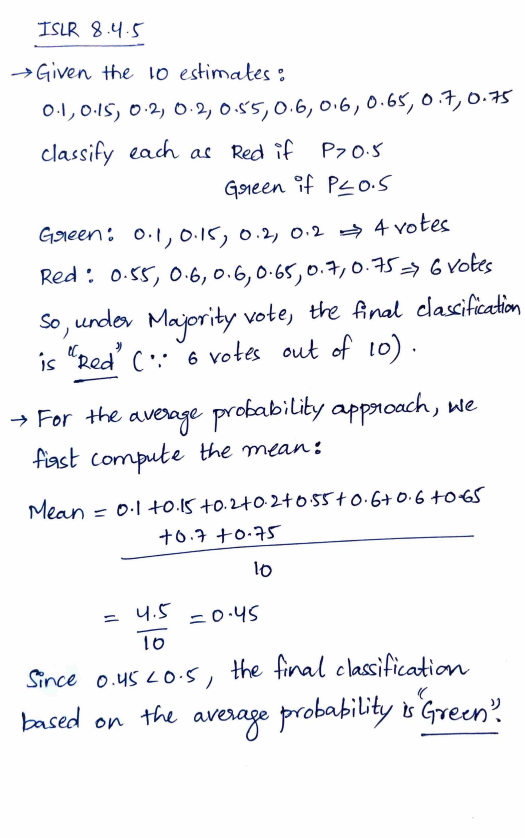

# 5. ISLR 9.7.3

### (a) Sketch the observations

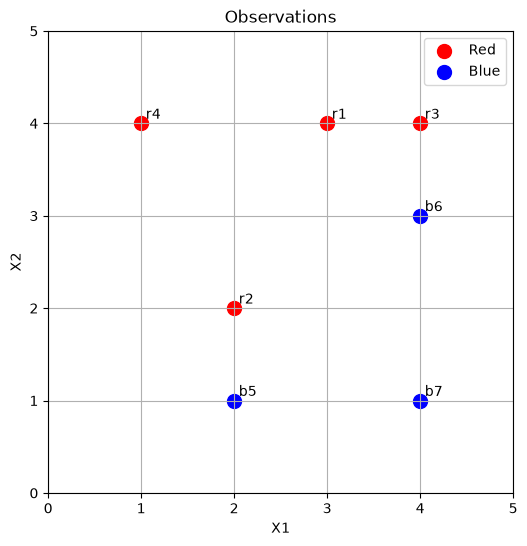

In [29]:
red = [(3, 4), (2, 2), (4, 4), (1, 4)]
blue = [(2, 1), (4, 3), (4, 1)]

red_x = [p[0] for p in red]
red_y = [p[1] for p in red]

blue_x = [p[0] for p in blue]
blue_y = [p[1] for p in blue]

plt.figure(figsize=(6, 6))

plt.scatter(red_x, red_y, color="red", s=100, label="Red")
plt.scatter(blue_x, blue_y, color="blue", s=100, label="Blue")

for i, (x, y) in enumerate(red, start=1):
    plt.text(x + 0.05, y + 0.05, f"r{i}", fontsize=10)

for i, (x, y) in enumerate(blue, start=5):
    plt.text(x + 0.05, y + 0.05, f"b{i}", fontsize=10)

plt.xlim(0, 5)
plt.ylim(0, 5)
plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Observations")
plt.grid(True)
plt.legend()
plt.show()

The observations are plotted in the X1-X2 plane as follows:
- Red: (3,4), (2,2), (4,4), (1,4)
- Blue: (2,1), (4,3), (4,1)

The red points lie mostly above the blue points, so the two classes are linearly separable.

### (b) Optimal Separating Hyperplane

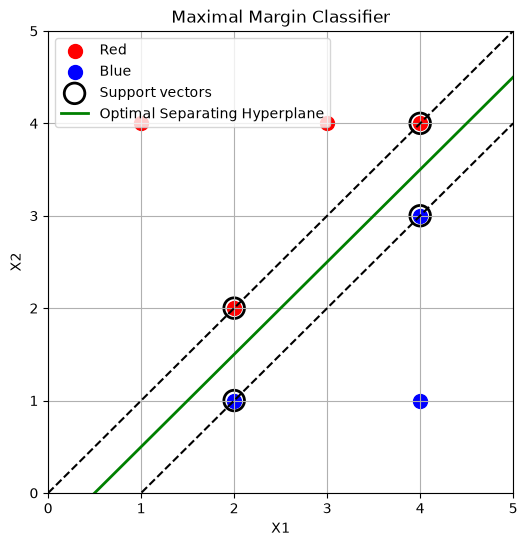

In [30]:
# Support points lie on the two parallel margin boundaries.
support_points = np.array([[2,2], [4,4], [4,3], [2,1]])

plt.figure(figsize=(6,6))

plt.scatter(red_x, red_y, c='red', s=100, label='Red')
plt.scatter(blue_x, blue_y, c='blue', s=100, label='Blue')

plt.scatter(support_points[:,0], support_points[:,1], s=220, label='Support vectors', facecolors='none', edgecolors='black', linewidth=2)

x_vals = np.linspace(0, 5, 100)

main_line = x_vals - 0.5

upper_margin = x_vals
lower_margin = x_vals - 1

plt.plot(x_vals, main_line, color='green', linewidth=2, label='Optimal Separating Hyperplane')
plt.plot(x_vals, upper_margin, linestyle='--', color='black')
plt.plot(x_vals, lower_margin, linestyle='--', color='black')

plt.xlabel("X1")
plt.ylabel("X2")
plt.xlim(0,5)
plt.ylim(0,5)
plt.title("Maximal Margin Classifier")
plt.legend()
plt.grid(True)
plt.show()

The closest red observations lie on $X_2=X_1$, and the closest blue
observations lie on $X_2=X_1-1$. The optimal separating line is halfway
between these parallel supporting lines:

$$X_2=X_1-\frac12.$$

In standard form, it is

$$\frac12-X_1+X_2=0.$$

### (c) Classification rule

Define

$$f(X)=\frac12-X_1+X_2.$$

Classify an observation as **Red if $f(X)>0$**, and **Blue otherwise**.
One valid coefficient vector is

$$\beta_0=\frac12,\qquad\beta_1=-1,\qquad\beta_2=1.$$

For example, the red point $(2,2)$ gives $f=1/2>0$, while the blue point
$(2,1)$ gives $f=-1/2<0$. Multiplying all coefficients by a positive constant
leaves this rule unchanged.

### (d) Margins

The dashed boundaries in the sketch are $X_2=X_1$ and $X_2=X_1-1$.
For $f(X)=1/2-X_1+X_2$, the normal vector has length $\sqrt2$.
Each supporting line is therefore at perpendicular distance

$$M=\frac{1/2}{\sqrt2}=\frac{1}{2\sqrt2}$$

from the separating line. The full width between the two supporting lines
is $2M=1/\sqrt2$.

### (e) Support vectors
The support vectors are the observations (circles) that lie exactly on the margin boundaries. 

From the plot, these points are:
- Red: (2,2), (4,4)
- Blue: (2,1), (4,3)

Thus, the support vectors are **(2,2), (4,4), (2,1), and (4,3)**. These points determine the maximal margin hyperplane.

### (f) Moving the seventh observation

Observation 7, $(4,1)$, is blue and is not a support vector. It lies strictly
outside the margin, farther from the separator than the blue support
vectors. A sufficiently small movement that keeps it outside the margin
does not change the supporting constraints, so the maximal margin
hyperplane remains unchanged.

### (g) A separating hyperplane that is not the optimal separating hyperplane

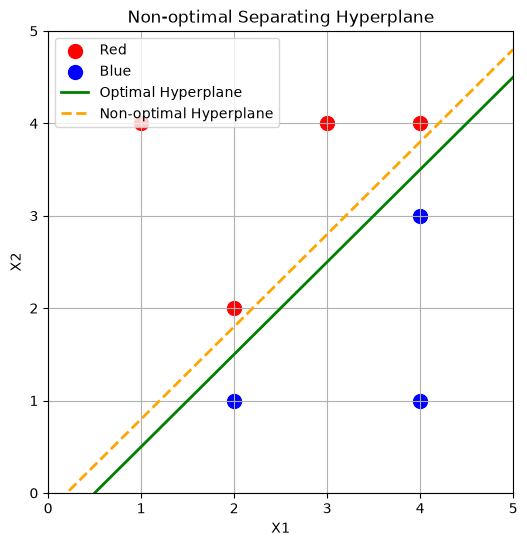

In [31]:
plt.figure(figsize=(6,6))

plt.scatter(red_x, red_y, c='red', s=100, label='Red')
plt.scatter(blue_x, blue_y, c='blue', s=100, label='Blue')

x_vals = np.linspace(0, 5, 100)

opt_line = x_vals - 0.5

non_opt_line = x_vals - 0.2

plt.plot(x_vals, opt_line, color='green', linewidth=2, label='Optimal Hyperplane')
plt.plot(x_vals, non_opt_line, color='orange', linestyle='--', linewidth=2, label='Non-optimal Hyperplane')

plt.xlabel("X1")
plt.ylabel("X2")
plt.xlim(0,5)
plt.ylim(0,5)
plt.title("Non-optimal Separating Hyperplane")
plt.legend()
plt.grid(True)
plt.show()

A separating hyperplane that is not the optimal separating hyperplane is:

   - X2 = X1 - 0.2

This line (orange dashed line) correctly separates the red and blue classes, but it is closer to one class and does not maximize the margin. Therefore, it is not the maximal margin hyperplane.


### (h) Add one additional observation so that the two classes are no longer separable by a hyperplane

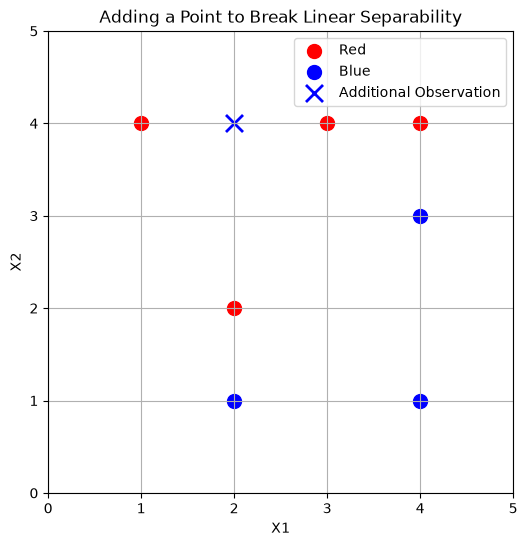

In [32]:
# A blue point on the red convex hull prevents strict linear separation.
added_blue_point = np.array([[2,4]])

plt.figure(figsize=(6,6))

plt.scatter(red_x, red_y, c='red', s=100, label='Red')
plt.scatter(blue_x, blue_y, c='blue', s=100, label='Blue')

plt.scatter(added_blue_point[:,0], added_blue_point[:,1], c='blue', marker='x', s=150, linewidths=2, label='Additional Observation')

plt.xlabel("X1")
plt.ylabel("X2")
plt.xlim(0,5)
plt.ylim(0,5)
plt.title("Adding a Point to Break Linear Separability")
plt.legend()
plt.grid(True)

plt.show()

Add a **Blue observation at $(2,4)$**. It lies on the line segment between
the red observations $(1,4)$ and $(4,4)$:

$$ (2,4)=\frac23(1,4)+\frac13(4,4). $$

A linear score that is positive at both red endpoints is also positive at
every convex combination of them, including $(2,4)$. It therefore cannot
assign the new point to Blue while assigning both endpoints to Red.
Consequently, the augmented classes are not linearly separable.

## References

- https://xgboost.readthedocs.io/en/stable/parameter.html
- https://xgboost.readthedocs.io/en/stable/tutorials/model.html
- https://scikit-learn.org/stable/common_pitfalls.html
- https://imbalanced-learn.org/stable/common_pitfalls.html
- https://seaborn.pydata.org/generated/seaborn.pairplot.html
- https://www.geeksforgeeks.org/machine-learning/linear-vs-non-linear-classification-
- https://www.geeksforgeeks.org/machine-learning/ml-bias-variance-trade-off/
- https://www.geeksforgeeks.org/machine-learning/smote-for-imbalanced-classification-with-python/


## AI used - ChatGPT (OpenAI)

### **Prompts**
- What is the step-by-step process for fitting and assessing an SVM binary classifier in Python, and how do you visualize its decision boundaries and margin limits?
- How do you utilize SMOTE to address skewed class distributions in Python while properly embedding it inside cross-validation loops to prevent data leakage?
- How can you set up a Random Forest model using scikit-learn, calculate the out-of-bag (OOB) error rate, and measure predictive performance via confusion matrices and ROC-AUC curves?
- How can you break down a confusion matrix to evaluate false positives and false negatives when dealing with heavily skewed class distributions?